# AG News fast experiment and report evidence



In [ ]:
import importlib.util, subprocess, sys, os, time
os.environ['HF_HUB_DOWNLOAD_TIMEOUT'] = '60'
os.environ['HF_HUB_ETAG_TIMEOUT'] = '30'
if importlib.util.find_spec('transformers') is None:
    subprocess.run([sys.executable,'-m','pip','install','-q','transformers==4.57.1'],check=True)
if importlib.util.find_spec('torch') is None:
    subprocess.run([sys.executable,'-m','pip','install','-q','torch>=2.6'],check=True)

## 1 Settings and metric helpers

In [ ]:
import copy, csv, gc, hashlib, html, io, json, platform, random, re, traceback, urllib.request, zipfile
from collections import Counter
from datetime import datetime, timezone
from importlib.metadata import version
from pathlib import Path
import numpy as np
import pandas as pd
import torch
from torch import nn
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score
from sklearn.pipeline import Pipeline
from threadpoolctl import threadpool_limits
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

STARTED = time.perf_counter()
SEED = 42
CFG = {'seed':SEED, 'train_size':4000, 'validation_size':800, 'test_size':1000,
       'max_length':64, 'cnn_epochs':3, 'cnn_batch_size':64, 'embedding_dim':64,
       'cnn_filters':32, 'cnn_kernels':[3,4,5], 'cnn_dropout':0.5, 'cnn_learning_rate':0.002,
       'bert_checkpoint':'prajjwal1/bert-tiny', 'bert_batch_size':64,
       'classifier_C':1.0, 'bootstrap_resamples':500, 'target_macro_f1':0.90, 'meaningful_gain':0.01,
       'encoder_budget_seconds':480, 'minimum_pilot_batches':3}
OUT = Path('/content/ag_news_fast_results') if Path('/content').exists() else Path.cwd()/'ag_news_fast_results'
OUT.mkdir(parents=True,exist_ok=True)
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.set_num_threads(2)
random.seed(SEED);np.random.seed(SEED);torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.benchmark=False
    torch.backends.cudnn.deterministic=True
LABELS=['World','Sports','Business','Sci/Tech']
NOTES=[];HISTORY=[];MODELS={};VALIDATION={};TIMING={};FAILURES={}
def save_json(name,obj):
    (OUT/name).write_text(json.dumps(obj,indent=2,allow_nan=False),encoding='utf-8')
def sha(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()
def score(y,pred):
    return {'n':len(y),'accuracy':float(accuracy_score(y,pred)),
            'macro_f1':float(f1_score(y,pred,labels=range(4),average='macro',zero_division=0)),
            'classification_report':classification_report(y,pred,labels=range(4),target_names=LABELS,output_dict=True,zero_division=0),
            'confusion_matrix':confusion_matrix(y,pred,labels=range(4)).tolist()}
ENV={'python':platform.python_version(),'platform':platform.platform(),'device':str(DEVICE),
     'gpu':torch.cuda.get_device_name(0) if DEVICE.type=='cuda' else None}
for package in ['numpy','pandas','scikit-learn','torch','transformers']:
    ENV[package]=version(package)
save_json('config.json',CFG);save_json('environment.json',ENV)
print('Device:',DEVICE,'| seed:',SEED,'| requested rows:',CFG['train_size'],CFG['validation_size'],CFG['test_size'])

Device: cpu | seed: 42 | requested rows: 4000 800 1000


## 2 Fixed data and leakage checks

The full original CSV files are downloaded once. Balanced samples are selected with fixed seeds. Training and validation come only from the original training file; the test subset comes only from the original official test file. Exact development duplicates, conflicting duplicate labels, and development-side matches to official test text are removed before sampling. Near-duplicate stories may remain.

In [ ]:
DATA_START=time.perf_counter()
raw=OUT/'raw';raw.mkdir(exist_ok=True)
BASE_URL='https://raw.githubusercontent.com/mhjabreel/CharCnn_Keras/master/data/ag_news_csv'
def normalize(s):return re.sub(r'\s+',' ',html.unescape(str(s))).strip()
def read_news(split):
    path=raw/f'{split}.csv'
    if not path.exists():
        print('Downloading',split,flush=True)
        with urllib.request.urlopen(f'{BASE_URL}/{split}.csv',timeout=120) as r:
            payload=r.read()
        path.write_bytes(payload)
    df=pd.read_csv(path,header=None,names=['label','title','description'],keep_default_na=False)
    df['id']=[f'{split}-{i:06d}' for i in range(len(df))]
    df['label']=df.label.astype(int)-1
    assert set(df.label)==set(range(4))
    df['title']=df.title.map(normalize);df['description']=df.description.map(normalize)
    df['text']=df.title+'\n'+df.description
    df['hash']=df.text.map(lambda x:hashlib.sha256(normalize(x).casefold().encode()).hexdigest())
    return df
original_train,official_test=read_news('train'),read_news('test')
development=original_train.copy()
conflicts=development.groupby('hash').label.nunique()
bad=set(conflicts[conflicts>1].index)
before=len(development);development=development[~development.hash.isin(bad)]
conflict_rows=before-len(development)
before=len(development);development=development.drop_duplicates('hash')
duplicate_rows=before-len(development)
before=len(development);development=development[~development.hash.isin(set(official_test.hash))]
overlap_rows=before-len(development)
train_parts=[];val_parts=[]
for label in range(4):
    selected=development[development.label==label].sample((CFG['train_size']+CFG['validation_size'])//4,random_state=SEED)
    val_parts.append(selected.iloc[:CFG['validation_size']//4])
    train_parts.append(selected.iloc[CFG['validation_size']//4:])
TRAIN=pd.concat(train_parts).sample(frac=1,random_state=SEED).reset_index(drop=True)
VAL=pd.concat(val_parts).sample(frac=1,random_state=SEED).reset_index(drop=True)
TEST=pd.concat([official_test[official_test.label==label].sample(CFG['test_size']//4,random_state=SEED+1)
                for label in range(4)]).sample(frac=1,random_state=SEED+1).reset_index(drop=True)
assert not set(TRAIN.hash)&set(VAL.hash)
assert not (set(TRAIN.hash)|set(VAL.hash))&set(TEST.hash)
AUDIT={'dataset':'AG News','source':BASE_URL,'input':'title plus description',
       'original_train_rows':len(original_train),'official_test_rows':len(official_test),
       'conflicting_rows_removed':conflict_rows,'duplicate_rows_removed':duplicate_rows,
       'train_test_overlap_rows_removed':overlap_rows,'split_seed':SEED,'test_sample_seed':SEED+1,
       'test_protocol':'fixed stratified subset of original official test file; not the full official test set',
       'near_duplicate_detection':'not performed','splits':{},
       'raw_sha256':{s:sha(raw/f'{s}.csv') for s in ['train','test']}}
for name,df in [('train',TRAIN),('validation',VAL),('test',TEST)]:
    AUDIT['splits'][name]={'rows':len(df),'class_counts':{LABELS[i]:int((df.label==i).sum()) for i in range(4)},
                         'row_ids':df.id.tolist()}
save_json('data_audit.json',AUDIT)
pd.concat([df.assign(split=name) for name,df in [('train',TRAIN),('validation',VAL),('test',TEST)]])[
    ['split','id','label','title','description']].to_csv(OUT/'selected_data.csv',index=False)
TIMING['data_preparation_seconds']=time.perf_counter()-DATA_START
print('Fixed splits:',len(TRAIN),len(VAL),len(TEST))
display(TRAIN[['title','description','label']].head())

Fixed splits: 4000 800 1000


,title,description,label
0,Israeli troops mass at Gaza border after cabin...,Armoured vehicles massed on Gaza #39;s border ...,0
1,3G rival i-Mode finally hits the UK,Mobile network operator O2 has completed a dea...,3
2,Blair spokesman denies snap election report,Downing Street has brushed aside reports that ...,0
3,Microsofts Latest Plan for TV,Microsoft is set to announce a renewed assault...,3
4,Japan Orders Citigroup to Close 4 Offices,TOKYO (Reuters) - Japan's financial regulator ...,2


## 3 Traditional baseline — TF-IDF plus Logistic Regression

In [ ]:
t=time.perf_counter()
baseline=Pipeline([('tfidf',TfidfVectorizer(ngram_range=(1,2),min_df=2,max_features=20000,sublinear_tf=True)),
                   ('classifier',LogisticRegression(C=CFG['classifier_C'],max_iter=500,random_state=SEED))])
with threadpool_limits(limits=2):baseline.fit(TRAIN.text,TRAIN.label)
MODELS['TFIDF_LogReg']=baseline
VALIDATION['TFIDF_LogReg']=score(VAL.label,baseline.predict(VAL.text))
TIMING['TFIDF_LogReg_training_seconds']=time.perf_counter()-t
print('Baseline validation macro-F1:',round(VALIDATION['TFIDF_LogReg']['macro_f1'],4))

Baseline validation macro-F1: 0.8781


## 4 CNN

Training-only vocabulary, 64-dimensional embeddings, three convolution widths, 32 filters per width, masked max pooling, dropout, and a four-class output. The best validation checkpoint is retained. The first epoch gives an early runtime check.

In [ ]:
def tokens(text):return re.findall(r'\w+|[^\w\s]',text.lower())
counts=Counter(w for text in TRAIN.text for w in tokens(text))
ranked=sorted(counts,key=lambda w:(-counts[w],w))[:11998]
VOCAB={'<PAD>':0,'<UNK>':1,**{w:i+2 for i,w in enumerate(ranked)}}
def encode_cnn(texts):
    ids=torch.zeros((len(texts),CFG['max_length']),dtype=torch.long)
    lengths=torch.ones(len(texts),dtype=torch.long)
    for i,text in enumerate(texts):
        values=[VOCAB.get(w,1) for w in tokens(text)[:CFG['max_length']]] or [1]
        ids[i,:len(values)]=torch.tensor(values);lengths[i]=len(values)
    return ids,lengths
class FastCNN(nn.Module):
    def __init__(self,dropout=0.5):
        super().__init__()
        self.embedding=nn.Embedding(len(VOCAB),CFG['embedding_dim'],padding_idx=0)
        self.convs=nn.ModuleList(nn.Conv1d(CFG['embedding_dim'],CFG['cnn_filters'],k) for k in CFG['cnn_kernels'])
        self.dropout=nn.Dropout(dropout)
        self.classifier=nn.Linear(CFG['cnn_filters']*len(CFG['cnn_kernels']),4)
    def forward(self,ids,lengths):
        x=self.embedding(ids).transpose(1,2);pooled=[]
        for conv in self.convs:
            z=torch.relu(conv(x))
            valid=(torch.arange(z.shape[2],device=z.device)[None,:] < (lengths-conv.kernel_size[0]+1).clamp(min=1)[:,None])
            pooled.append(z.masked_fill(~valid[:,None,:],torch.finfo(z.dtype).min).max(2).values)
        return self.classifier(self.dropout(torch.cat(pooled,dim=1)))
def cnn_probabilities(model,texts,batch_size=128):
    model.eval();out=[]
    with torch.inference_mode():
        for start in range(0,len(texts),batch_size):
            x,l=encode_cnn(list(texts)[start:start+batch_size])
            out.append(model(x.to(DEVICE),l.to(DEVICE)).softmax(1).cpu().numpy())
    return np.concatenate(out)
def fit_cnn(name,dropout=0.5):
    torch.manual_seed(SEED)
    if DEVICE.type=='cuda':torch.cuda.manual_seed_all(SEED)
    model=FastCNN(dropout).to(DEVICE)
    opt=torch.optim.Adam(model.parameters(),lr=CFG['cnn_learning_rate'])
    x,l=encode_cnn(TRAIN.text.tolist());y=torch.tensor(TRAIN.label.to_numpy(),dtype=torch.long)
    loader=torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x,l,y),batch_size=CFG['cnn_batch_size'],
                shuffle=True,generator=torch.Generator().manual_seed(SEED))
    best=-1;best_weights=None;t=time.perf_counter()
    for epoch in range(1,CFG['cnn_epochs']+1):
        epoch_start=time.perf_counter();model.train();loss_total=0.
        for bx,bl,by in loader:
            opt.zero_grad(set_to_none=True)
            loss=nn.functional.cross_entropy(model(bx.to(DEVICE),bl.to(DEVICE)),by.to(DEVICE))
            loss.backward();nn.utils.clip_grad_norm_(model.parameters(),1.);opt.step()
            loss_total+=loss.item()*len(by)
        vp=cnn_probabilities(model,VAL.text.tolist())
        result=score(VAL.label,vp.argmax(1))
        row={'model':name,'epoch':epoch,'train_loss':loss_total/len(TRAIN),
             'validation_macro_f1':result['macro_f1'],'validation_accuracy':result['accuracy'],
             'epoch_seconds':time.perf_counter()-epoch_start}
        HISTORY.append(row);print(name,row,flush=True)
        if result['macro_f1']>best:
            best=result['macro_f1'];best_weights={k:v.detach().cpu().clone() for k,v in model.state_dict().items()}
    model.load_state_dict(best_weights);model.eval()
    MODELS[name]=model
    VALIDATION[name]=score(VAL.label,cnn_probabilities(model,VAL.text.tolist()).argmax(1))
    TIMING[name+'_training_seconds']=time.perf_counter()-t
    return model
cnn=fit_cnn('CNN')
pd.DataFrame(HISTORY).to_csv(OUT/'training_history.csv',index=False)
NOTES.append('CNN uses three epochs and one fixed seed; no across-seed variability estimate is available.')

CNN {'model': 'CNN', 'epoch': 1, 'train_loss': 1.4353517236709594, 'validation_macro_f1': 0.5027499646102784, 'validation_accuracy': 0.5325, 'epoch_seconds': 3.016477442999985}
CNN {'model': 'CNN', 'epoch': 2, 'train_loss': 1.2202664747238159, 'validation_macro_f1': 0.6011772363326727, 'validation_accuracy': 0.6075, 'epoch_seconds': 1.855706160000068}
CNN {'model': 'CNN', 'epoch': 3, 'train_loss': 1.0477560439109803, 'validation_macro_f1': 0.6698846308021812, 'validation_accuracy': 0.66875, 'epoch_seconds': 1.853989757000022}


## 5 Compact pretrained Transformer and inexpensive controlled comparison

BERT-Tiny has two Transformer layers with hidden size 128. Its encoder stays frozen. We fit a Logistic Regression head on masked mean token features and another on CLS features. The mean excludes padding and special tokens. Both heads use the same records, regularization, solver, and encoder outputs, so only pooling changes. **This is feature transfer, not full Transformer fine-tuning.**

The first batches estimate feature-extraction runtime. If the stage would exceed the eight-minute encoder allowance or loading fails, the notebook records the reason and runs a cheap CNN dropout ablation instead, preserving a baseline plus a controlled comparison.

In [ ]:
BERT_INFO={'status':'not_started'};FEATURES={};encoder=None;tokenizer=None
try:
    from transformers import AutoTokenizer,AutoModel
    load_start=time.perf_counter()
    tokenizer=AutoTokenizer.from_pretrained(CFG['bert_checkpoint'])
    encoder=AutoModel.from_pretrained(CFG['bert_checkpoint'],attn_implementation='eager').to(DEVICE).eval()
    for param in encoder.parameters():param.requires_grad=False
    BERT_INFO={'status':'running','checkpoint':CFG['bert_checkpoint'],
        'resolved_revision':getattr(encoder.config,'_commit_hash',None),
        'layers':encoder.config.num_hidden_layers,'hidden_size':encoder.config.hidden_size,
        'parameters':sum(p.numel() for p in encoder.parameters()),'encoder_frozen':True,
        'load_seconds':time.perf_counter()-load_start}
    encoder_started=time.perf_counter();total_n=len(TRAIN)+len(VAL)+len(TEST)
    def bert_features(texts,check_budget=False):
        mean_parts=[];cls_parts=[];lengths=[];start_clock=time.perf_counter()
        for start in range(0,len(texts),CFG['bert_batch_size']):
            part=list(texts)[start:start+CFG['bert_batch_size']]
            enc=tokenizer(part,padding='max_length',truncation=True,max_length=CFG['max_length'],
                          return_special_tokens_mask=True,return_tensors='pt')
            specials=enc.pop('special_tokens_mask').to(DEVICE)
            enc={k:v.to(DEVICE) for k,v in enc.items()}
            with torch.inference_mode():
                hidden=encoder(**enc).last_hidden_state
                mask=(enc['attention_mask']*(1-specials)).unsqueeze(-1)
                mean=(hidden*mask).sum(1)/mask.sum(1).clamp(min=1)
                mean_parts.append(mean.cpu().numpy());cls_parts.append(hidden[:,0].cpu().numpy())
            if DEVICE.type=='cuda':torch.cuda.synchronize()
            if check_budget and start//CFG['bert_batch_size']+1==CFG['minimum_pilot_batches']:
                processed=min(start+len(part),len(texts))
                estimate=(time.perf_counter()-start_clock)/processed*total_n
                BERT_INFO['estimated_feature_seconds']=estimate
                print('Estimated encoder feature time:',round(estimate,1),'seconds',flush=True)
                if estimate>CFG['encoder_budget_seconds']:
                    raise TimeoutError('Encoder pilot exceeds the configured feature-extraction budget')
            if time.perf_counter()-encoder_started>CFG['encoder_budget_seconds']:
                raise TimeoutError('Encoder feature-extraction time allowance reached')
        return {'mean':np.concatenate(mean_parts),'cls':np.concatenate(cls_parts)}
    # Test text features are computed here without using test labels for model selection.
    for split,frame in [('train',TRAIN),('validation',VAL),('test',TEST)]:
        FEATURES[split]=bert_features(frame.text.tolist(),check_budget=(split=='train'))
        print('Encoded',split,len(frame),flush=True)
    TIMING['BERT_feature_extraction_seconds']=time.perf_counter()-encoder_started
    for name,pooling in [('BERT_Tiny_mean','mean'),('BERT_Tiny_CLS','cls')]:
        t=time.perf_counter()
        head=LogisticRegression(C=CFG['classifier_C'],max_iter=500,random_state=SEED)
        with threadpool_limits(limits=2):head.fit(FEATURES['train'][pooling],TRAIN.label)
        MODELS[name]=head
        VALIDATION[name]=score(VAL.label,head.predict(FEATURES['validation'][pooling]))
        TIMING[name+'_head_training_seconds']=time.perf_counter()-t
        print(name,'validation macro-F1:',round(VALIDATION[name]['macro_f1'],4),flush=True)
    BERT_INFO['status']='completed'
    ABLATION={'a':'BERT_Tiny_mean','b':'BERT_Tiny_CLS','changed':'masked mean pooling versus CLS pooling',
              'controlled':'same frozen encoder forward pass, input text, splits, classifier C, seed and solver'}
    NOTES.append('BERT-Tiny frozen-feature transfer replaces DistilBERT fine-tuning to meet the time budget.')
except Exception as error:
    BERT_INFO['status']='failed_or_budget_exceeded';BERT_INFO['reason']=str(error)
    FAILURES['transformer']=traceback.format_exc()
    print('Transformer stage not completed:',error,'— running CNN dropout ablation.',flush=True)
    for name in ['BERT_Tiny_mean','BERT_Tiny_CLS']:
        MODELS.pop(name,None);VALIDATION.pop(name,None)
    fit_cnn('CNN_no_dropout',dropout=0.)
    ABLATION={'a':'CNN','b':'CNN_no_dropout','changed':'dropout 0.5 versus 0.0',
              'controlled':'same initialization seed, training order, architecture, data, optimizer and epoch budget'}
    NOTES.append('Transformer was not completed; the CNN dropout comparison is the controlled ablation. See failures.json.')
save_json('transformer_details.json',BERT_INFO)
save_json('ablation_design.json',ABLATION)
save_json('validation_metrics.json',VALIDATION)
save_json('failures.json',FAILURES)
pd.DataFrame(HISTORY).to_csv(OUT/'training_history.csv',index=False)
display(pd.DataFrame([{'model':k,'validation_macro_f1':v['macro_f1'],'validation_accuracy':v['accuracy']}
                     for k,v in VALIDATION.items()]))

config.json:   0%|          | 0.00/285 [00:00<?, ?B/s]

Transformer stage not completed: Couldn't instantiate the backend tokenizer from one of: 
(1) a `tokenizers` library serialization file, 
(2) a slow tokenizer instance to convert or 
(3) an equivalent slow tokenizer class to instantiate and convert. 
You need to have sentencepiece or tiktoken installed to convert a slow tokenizer to a fast one. — running CNN dropout ablation.
CNN_no_dropout {'model': 'CNN_no_dropout', 'epoch': 1, 'train_loss': 1.2560667114257813, 'validation_macro_f1': 0.5533614953197273, 'validation_accuracy': 0.565, 'epoch_seconds': 2.840564793999988}
CNN_no_dropout {'model': 'CNN_no_dropout', 'epoch': 2, 'train_loss': 0.8243283557891846, 'validation_macro_f1': 0.6378933424332363, 'validation_accuracy': 0.64375, 'epoch_seconds': 1.7836416419999068}
CNN_no_dropout {'model': 'CNN_no_dropout', 'epoch': 3, 'train_loss': 0.4681172432899475, 'validation_macro_f1': 0.6976816362033295, 'validation_accuracy': 0.705, 'epoch_seconds': 1.8008054790000187}


,model,validation_macro_f1,validation_accuracy
0,TFIDF_LogReg,0.878065,0.87875
1,CNN,0.669885,0.66875
2,CNN_no_dropout,0.697682,0.70500


## 6 Lock the choices and evaluate the held-out subset

The primary reported metric is macro-F1, alongside accuracy and per-class precision/recall/F1. The fixed test subset is 1,000 examples, not the full official 7,600-example test set. The paired bootstrap uses the same sampled test rows for both compared models; its interval does not measure training-seed variability.

In [ ]:
LOCK={'config':CFG,'completed_models':list(MODELS),'checkpoint_selection':'CNN maximum validation macro-F1',
      'hyperparameters':'fixed beforehand; no test-driven tuning','test_rows':len(TEST),
      'locked_at':datetime.now(timezone.utc).isoformat()}
save_json('experiment_protocol.json',LOCK)
PREDICTIONS={};TEST_METRICS={};RESULT_ROWS=[]
for name,model in MODELS.items():
    t=time.perf_counter()
    if name=='TFIDF_LogReg':probs=model.predict_proba(TEST.text)
    elif name.startswith('CNN'):probs=cnn_probabilities(model,TEST.text.tolist())
    else:probs=model.predict_proba(FEATURES['test']['mean' if name.endswith('mean') else 'cls'])
    elapsed=time.perf_counter()-t
    pred=probs.argmax(1);TEST_METRICS[name]=score(TEST.label,pred)
    frame=TEST[['id','title','description','label']].copy()
    frame['true_topic']=[LABELS[i] for i in TEST.label]
    frame['predicted_label']=pred;frame['predicted_topic']=[LABELS[i] for i in pred]
    frame['confidence_uncalibrated']=probs.max(1);frame['correct']=pred==TEST.label.to_numpy()
    frame['word_count']=TEST.text.str.split().map(len)
    for i,label in enumerate(LABELS):frame[f'p_{label}']=probs[:,i]
    frame.to_csv(OUT/f'predictions_{name}.csv',index=False)
    PREDICTIONS[name]=frame
    RESULT_ROWS.append({'model':name,'validation_macro_f1':VALIDATION[name]['macro_f1'],
       'test_macro_f1':TEST_METRICS[name]['macro_f1'],'test_accuracy':TEST_METRICS[name]['accuracy'],
       'prediction_seconds':elapsed,'timing_note':'BERT head prediction only; shared encoder cost is in timings.json' if name.startswith('BERT') else 'includes text processing'})
RESULTS=pd.DataFrame(RESULT_ROWS);RESULTS.to_csv(OUT/'results.csv',index=False)
save_json('test_metrics.json',TEST_METRICS)
def paired_interval(a,b,resamples=500):
    y=TEST.label.to_numpy();pa=PREDICTIONS[a].predicted_label.to_numpy();pb=PREDICTIONS[b].predicted_label.to_numpy()
    def fast_f1(y,p):
        cm=np.bincount(y*4+p,minlength=16).reshape(4,4);den=cm.sum(0)+cm.sum(1)
        return np.divide(2*cm.diagonal(),den,out=np.zeros(4),where=den!=0).mean()
    rng=np.random.default_rng(SEED);differences=[]
    for _ in range(resamples):
        idx=rng.integers(0,len(y),len(y));differences.append(fast_f1(y[idx],pa[idx])-fast_f1(y[idx],pb[idx]))
    return {'a':a,'b':b,'macro_f1_difference':float(fast_f1(y,pa)-fast_f1(y,pb)),
            'paired_bootstrap_ci95':np.quantile(differences,[.025,.975]).tolist(),'resamples':resamples,
            'scope':'test-example uncertainty for fixed trained models, not across-seed uncertainty'}
COMPARISONS={'ablation':paired_interval(ABLATION['a'],ABLATION['b'],CFG['bootstrap_resamples'])}
if BERT_INFO['status']=='completed':
    simpler=max(['TFIDF_LogReg','CNN'],key=lambda k:VALIDATION[k]['macro_f1'])
    COMPARISONS['transformer_vs_best_simpler_by_validation']=paired_interval('BERT_Tiny_mean',simpler,CFG['bootstrap_resamples'])
save_json('paired_comparisons.json',COMPARISONS)
display(RESULTS)
print(json.dumps(COMPARISONS,indent=2))

,model,validation_macro_f1,test_macro_f1,test_accuracy,prediction_seconds,timing_note
0,TFIDF_LogReg,0.878065,0.876535,0.877,0.072567,includes text processing
1,CNN,0.669885,0.661914,0.659,0.163126,includes text processing
2,CNN_no_dropout,0.697682,0.711671,0.716,0.161317,includes text processing


{
  "ablation": {
    "a": "CNN",
    "b": "CNN_no_dropout",
    "macro_f1_difference": -0.04975714643542106,
    "paired_bootstrap_ci95": [
      -0.07892563413038105,
      -0.018461872286673495
    ],
    "resamples": 500,
    "scope": "test-example uncertainty for fixed trained models, not across-seed uncertainty"
  }
}


## 7 Plots and failure examples

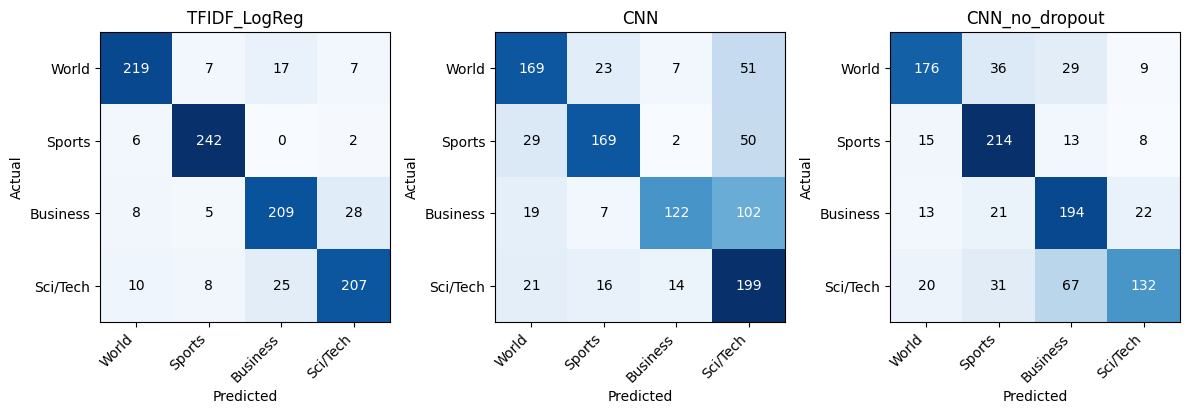

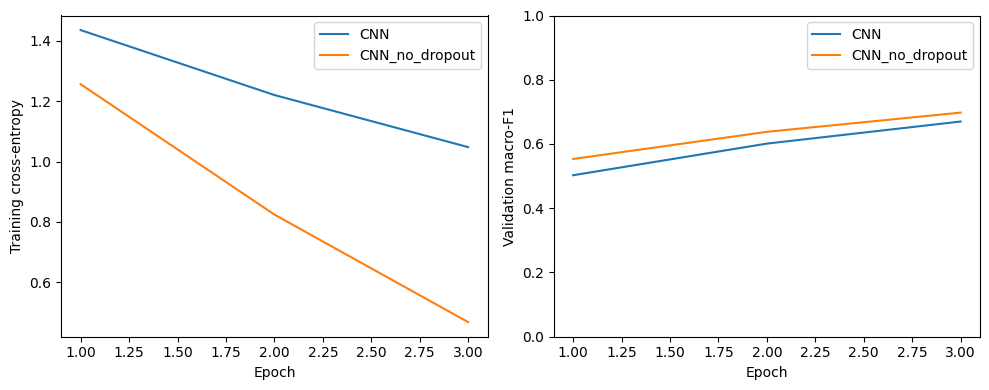

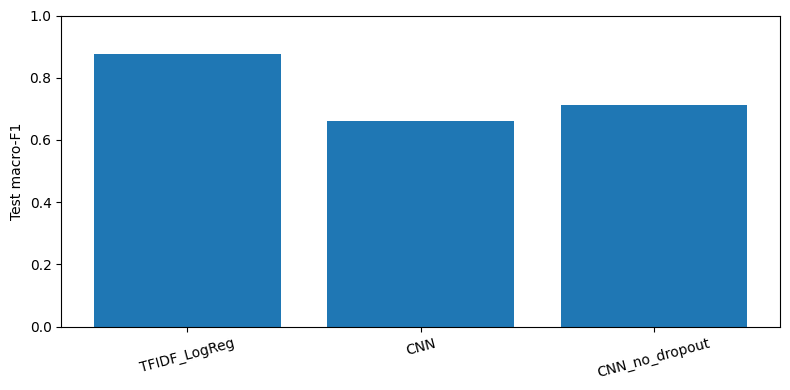

,title,description,true_topic,predicted_topic,confidence_uncalibrated
354,Cricket: Dubai global academy,The International Cricket Council are to open ...,World,Sci/Tech,0.416899
11,THE UNFOLDING UNIFORM,Pakistan is inherently unstable. Dealing with ...,World,Sports,0.507397
267,Why Putin is backing Kyoto again,Why did Russian President Vladimir Putin decid...,World,Sports,0.527956
361,Milosevic #39;s Lawyers to Appeal Own Appointment,"THE HAGUE, Netherlands -- The two lawyers repr...",World,Sci/Tech,0.374695
229,Bush 'picks new attorney general',White House legal counsel Alberto Gonzales is ...,World,Sci/Tech,0.365294
439,Glory Comes Amid Empty Seats and Closed Shutters,"HERE in Old Europe, people install shutters ou...",Sports,Sci/Tech,0.332949
25,England held up in Zimbabwe,Zimbabwe held up England #39;s charge as they ...,Sports,World,0.338470
322,Irish eyes turn to Clements ; Notre Dame inter...,Buffalo Bills offensive coordinator Tom Clemen...,Sports,World,0.341928
446,Big Game Hunting,"Virginia, Navy and Maryland face season-defini...",Sports,Sci/Tech,0.340030
258,They #39;re not on same side,Unable to reach an agreement on a one-year dea...,Sports,World,0.377704


Review these errors. Plausible categories: mixed topics, short text, ambiguity, unfamiliar names, truncation, or label concerns.


In [ ]:
fig,axes=plt.subplots(1,len(MODELS),figsize=(4*len(MODELS),4),squeeze=False)
for ax,(name,result) in zip(axes[0],TEST_METRICS.items()):
    cm=np.array(result['confusion_matrix']);ax.imshow(cm,cmap='Blues')
    for i in range(4):
        for j in range(4):ax.text(j,i,str(cm[i,j]),ha='center',va='center',color='white' if cm[i,j]>cm.max()/2 else 'black')
    ax.set_xticks(range(4),LABELS,rotation=45,ha='right');ax.set_yticks(range(4),LABELS)
    ax.set(title=name,xlabel='Predicted',ylabel='Actual')
fig.tight_layout();fig.savefig(OUT/'confusion_matrices.png',dpi=160);plt.show()
fig,axes=plt.subplots(1,2,figsize=(10,4));history=pd.DataFrame(HISTORY)
for name,part in history.groupby('model'):
    axes[0].plot(part.epoch,part.train_loss,label=name)
    axes[1].plot(part.epoch,part.validation_macro_f1,label=name)
axes[0].set(xlabel='Epoch',ylabel='Training cross-entropy');axes[1].set(xlabel='Epoch',ylabel='Validation macro-F1',ylim=(0,1))
axes[0].legend();axes[1].legend();fig.tight_layout();fig.savefig(OUT/'learning_curves.png',dpi=160);plt.show()
fig,ax=plt.subplots(figsize=(8,4));ax.bar(RESULTS.model,RESULTS.test_macro_f1);ax.set(ylabel='Test macro-F1',ylim=(0,1))
ax.tick_params(axis='x',rotation=15);fig.tight_layout();fig.savefig(OUT/'model_comparison.png',dpi=160);plt.show()
ERROR_MODEL='BERT_Tiny_mean' if BERT_INFO['status']=='completed' else 'CNN'
candidate=PREDICTIONS[ERROR_MODEL];errors=candidate[~candidate.correct]
sample=pd.concat([g.sample(min(5,len(g)),random_state=SEED) for _,g in errors.groupby('label')]) if len(errors) else errors.copy()
sample['failure_category']='';sample['analysis_notes']=''
for name,frame in PREDICTIONS.items():sample[f'{name}_prediction']=sample.id.map(frame.set_index('id').predicted_topic)
sample.to_csv(OUT/'error_analysis.csv',index=False)
candidate[candidate.correct].sample(min(8,int(candidate.correct.sum())),random_state=SEED).to_csv(OUT/'correct_examples.csv',index=False)
errors.sort_values('confidence_uncalibrated',ascending=False).head(20).to_csv(OUT/'confident_errors.csv',index=False)
slice_rows=[]
for name,frame in PREDICTIONS.items():
    for band,part in frame.groupby(pd.cut(frame.word_count,[-1,20,50,100,np.inf],labels=['0-20','21-50','51-100','101+']),observed=True):
        result=score(part.label,part.predicted_label)
        slice_rows.append({'model':name,'word_count_band':str(band),'n':len(part),'accuracy':result['accuracy'],'macro_f1':result['macro_f1']})
pd.DataFrame(slice_rows).to_csv(OUT/'length_slices.csv',index=False)
display(sample[['title','description','true_topic','predicted_topic','confidence_uncalibrated']])
print('Review these errors. Plausible categories: mixed topics, short text, ambiguity, unfamiliar names, truncation, or label concerns.')

## 8 Prediction demonstration and truncation audit

Inference uses the trained model and saved preprocessing. This demonstrates that the pipeline predicts new text. The software also records how often the fixed token cap truncated the inputs. Predictions are not fact checking and the probabilities are not calibrated.

In [ ]:
def predict_article(title,description):
    text=normalize(title)+'\n'+normalize(description)
    if BERT_INFO['status']=='completed':
        # A separate single prediction avoids changing the timing budget for extraction.
        enc=tokenizer([text],padding='max_length',truncation=True,max_length=CFG['max_length'],
                      return_special_tokens_mask=True,return_tensors='pt')
        specials=enc.pop('special_tokens_mask').to(DEVICE);enc={k:v.to(DEVICE) for k,v in enc.items()}
        with torch.inference_mode():
            hidden=encoder(**enc).last_hidden_state;mask=(enc['attention_mask']*(1-specials)).unsqueeze(-1)
            features=((hidden*mask).sum(1)/mask.sum(1).clamp(min=1)).cpu().numpy()
        name='BERT_Tiny_mean';prob=MODELS[name].predict_proba(features)[0]
    else:
        name='CNN';prob=cnn_probabilities(MODELS[name],[text])[0]
    return {'model':name,'title':title,'description':description,'predicted_topic':LABELS[int(prob.argmax())],
            'uncalibrated_probabilities':dict(zip(LABELS,map(float,prob)))}
DEMO=predict_article('National team wins football championship','The players celebrated their victory in the tournament final.')
save_json('inference_example.json',DEMO);print(json.dumps(DEMO,indent=2))
TRUNCATION={}
for split,frame in [('train',TRAIN),('validation',VAL),('test',TEST)]:
    entry={'cnn_fraction':float(np.mean([len(tokens(t))>CFG['max_length'] for t in frame.text]))}
    if BERT_INFO['status']=='completed':
        token_ids=tokenizer(frame.text.tolist(),truncation=False)['input_ids']
        entry['bert_fraction']=float(np.mean([len(ids)>CFG['max_length'] for ids in token_ids]))
    TRUNCATION[split]=entry
save_json('truncation_audit.json',TRUNCATION)

{
  "model": "CNN",
  "title": "National team wins football championship",
  "description": "The players celebrated their victory in the tournament final.",
  "predicted_topic": "Sports",
  "uncalibrated_probabilities": {
    "World": 0.04146105796098709,
    "Sports": 0.8534967303276062,
    "Business": 0.0422859787940979,
    "Sci/Tech": 0.06275614351034164
  }
}
